# CSE428 project — Oxford-IIIT Pet Attention U-Net



## 1. Imports and device

In [ ]:
# Course-aligned imports
# The structure follows the PyTorch/skimage/sklearn approach
import os
import random
import tarfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skimage
from skimage import io, transform

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Device: cpu


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

ROOT_DIR = Path("/content/drive/MyDrive/CSE428_Oxford_Pets")
CHECKPOINT_DIR = ROOT_DIR / "checkpoints"

print(list(CHECKPOINT_DIR.glob("*")))

Mounted at /content/drive
[PosixPath('/content/drive/MyDrive/CSE428_Oxford_Pets/checkpoints/base_unet_best.pt'), PosixPath('/content/drive/MyDrive/CSE428_Oxford_Pets/checkpoints/base_unet_last.pt'), PosixPath('/content/drive/MyDrive/CSE428_Oxford_Pets/checkpoints/attention_unet_best.pt'), PosixPath('/content/drive/MyDrive/CSE428_Oxford_Pets/checkpoints/attention_unet_last.pt')]


## 2. Reproducibility, Google Drive and directories

In [ ]:
# Reproducibility
SEED = 428

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything()

# We save checkpoints to Google Drive so training can be resumed in a new Colab session.
# Run this cell in Colab. If Drive mounting is unavailable, the code falls back to /content.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT_DIR = Path("/content/drive/MyDrive/CSE428_Oxford_Pets")
    print("successful login")
except Exception:
    print("failed to mount")
    ROOT_DIR = Path("/content/CSE428_Oxford_Pets")

DATA_DIR = ROOT_DIR / "data"
CHECKPOINT_DIR = ROOT_DIR / "checkpoints"
RESULT_DIR = ROOT_DIR / "results"
DATA_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT_DIR:", ROOT_DIR)
print("CHECKPOINT_DIR:", CHECKPOINT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
successful login
ROOT_DIR: /content/drive/MyDrive/CSE428_Oxford_Pets
CHECKPOINT_DIR: /content/drive/MyDrive/CSE428_Oxford_Pets/checkpoints


In [ ]:
from pathlib import Path

p = Path("/content/drive/MyDrive/CSE428_Oxford_Pets/checkpoints")

print(p.exists())
print(list(p.glob("*")))

False
[]


## 3. Download/extract dataset

In [ ]:
# Download the official Oxford-IIIT Pet images and annotations.
# The assignment explicitly allows alternate mirrors, but the official source is used here.
images_tar = DATA_DIR / "images.tar.gz"
annotations_tar = DATA_DIR / "annotations.tar.gz"
images_dir = DATA_DIR / "images"
annotations_dir = DATA_DIR / "annotations"

def download_file(url, destination):
    if not destination.exists():
        print("Downloading:", url)
        urllib.request.urlretrieve(url, destination)
    else:
        print("Already exists:", destination)

download_file(
    "https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz",
    images_tar
)
download_file(
    "https://www.robots.ox.ac.uk/~vgg/data/pets/data/annotations.tar.gz",
    annotations_tar
)

if not images_dir.exists():
    print("Extracting images...")
    with tarfile.open(images_tar, "r:gz") as tar:
        tar.extractall(DATA_DIR)

if not annotations_dir.exists():
    print("Extracting annotations...")
    with tarfile.open(annotations_tar, "r:gz") as tar:
        tar.extractall(DATA_DIR)

print("Images:", images_dir)
print("Annotations:", annotations_dir)


Already exists: /content/drive/MyDrive/CSE428_Oxford_Pets/data/images.tar.gz
Already exists: /content/drive/MyDrive/CSE428_Oxford_Pets/data/annotations.tar.gz
Images: /content/drive/MyDrive/CSE428_Oxford_Pets/data/images
Annotations: /content/drive/MyDrive/CSE428_Oxford_Pets/data/annotations


## 4. Load image/class/trimap metadata

In [ ]:
# Read Oxford-IIIT Pet file names, class IDs and segmentation trimaps.
# list.txt contains the breed/class ID for each image.
list_file = annotations_dir / "list.txt"
trimap_dir = annotations_dir / "trimaps"

rows = []
with open(list_file, "r") as f:
    for line in f:
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        parts = line.split()
        image_name = parts[0]
        class_id = int(parts[1]) - 1  # convert 1..37 to 0..36
        species_id = int(parts[2])
        breed_id = int(parts[3])
        rows.append((image_name, class_id, species_id, breed_id))

df = pd.DataFrame(rows, columns=["image_name", "class_id", "species_id", "breed_id"])
df["image_path"] = df["image_name"].map(lambda x: str(images_dir / (x + ".jpg")))
df["trimap_path"] = df["image_name"].map(lambda x: str(trimap_dir / (x + ".png")))

print("Total images:", len(df))
print("Number of classes:", df["class_id"].nunique())
print(df.head())


Total images: 7349
Number of classes: 37
       image_name  class_id  species_id  breed_id  \
0  Abyssinian_100         0           1         1   
1  Abyssinian_101         0           1         1   
2  Abyssinian_102         0           1         1   
3  Abyssinian_103         0           1         1   
4  Abyssinian_104         0           1         1   

                                          image_path  \
0  /content/drive/MyDrive/CSE428_Oxford_Pets/data...   
1  /content/drive/MyDrive/CSE428_Oxford_Pets/data...   
2  /content/drive/MyDrive/CSE428_Oxford_Pets/data...   
3  /content/drive/MyDrive/CSE428_Oxford_Pets/data...   
4  /content/drive/MyDrive/CSE428_Oxford_Pets/data...   

                                         trimap_path  
0  /content/drive/MyDrive/CSE428_Oxford_Pets/data...  
1  /content/drive/MyDrive/CSE428_Oxford_Pets/data...  
2  /content/drive/MyDrive/CSE428_Oxford_Pets/data...  
3  /content/drive/MyDrive/CSE428_Oxford_Pets/data...  
4  /content/drive/MyDrive/CS

## 5. Boundary pixels → foreground

In [ ]:
# Oxford trimap values:
# 1 = foreground, 2 = background, 3 = boundary.
# Assignment requirement: boundary/unclassified pixels must become foreground.
# Therefore every pixel whose trimap is NOT background (2) becomes foreground.
def trimap_to_foreground(trimap):
    trimap = np.asarray(trimap)
    return (trimap != 2).astype(np.float32)

# Sanity check on one sample.
sample_trim = io.imread(df.iloc[0]["trimap_path"])
binary_sample = trimap_to_foreground(sample_trim)

print("Trimap unique values:", np.unique(sample_trim))
print("Binary mask unique values:", np.unique(binary_sample))


Trimap unique values: [1 2 3]
Binary mask unique values: [0. 1.]


## 6. Preprocessing and 3×3 random visualization

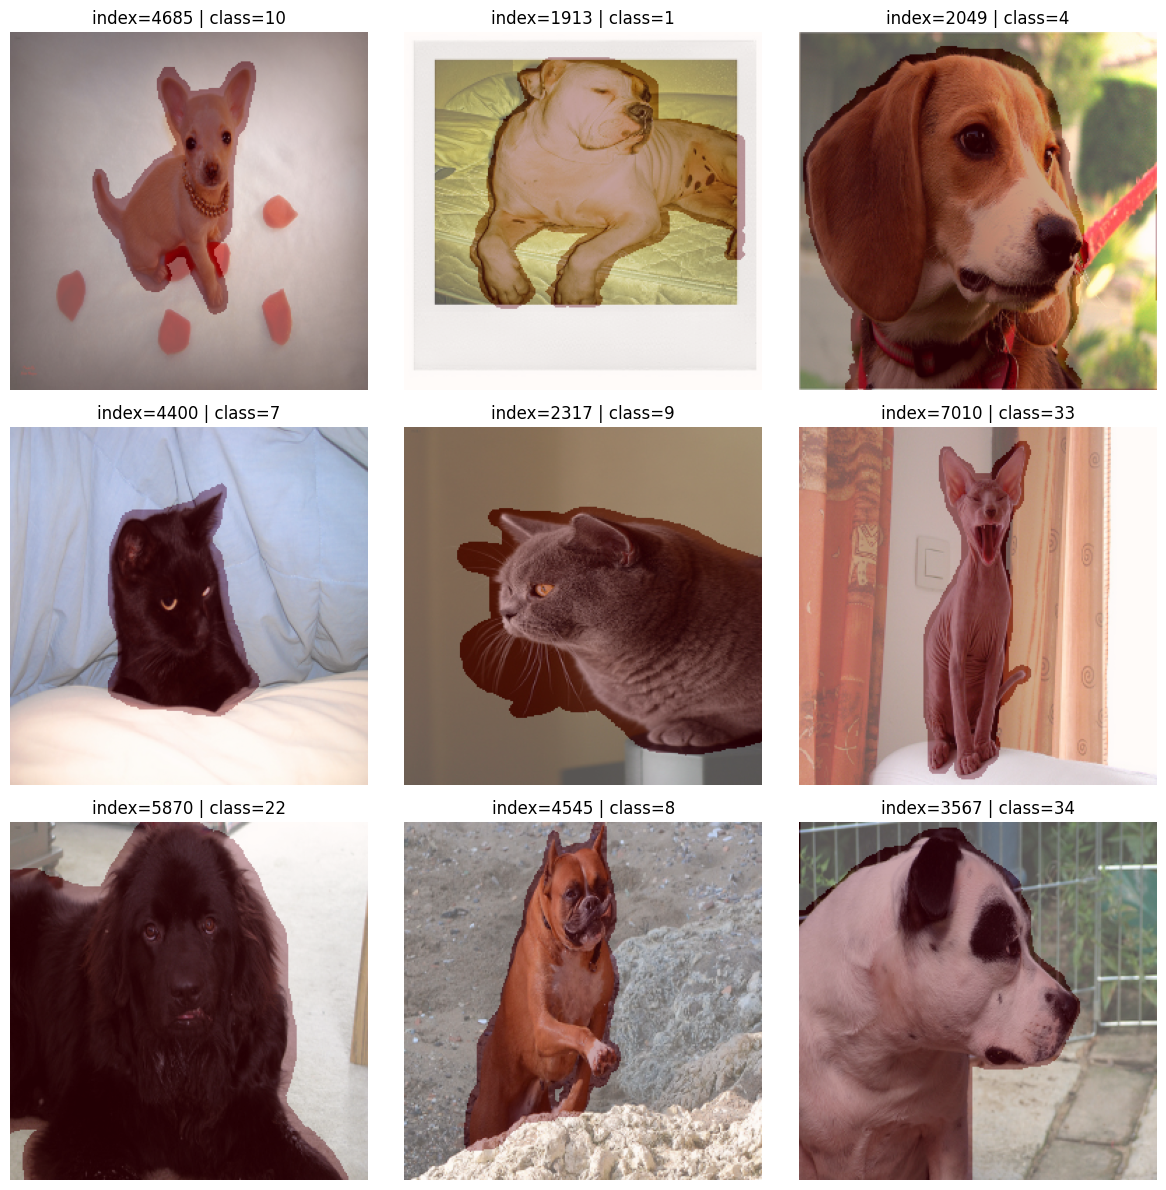

In [ ]:
def load_pair(row, image_size=(256, 256)):
    image = io.imread(row["image_path"])
    if image.ndim == 2:
        image = np.stack([image] * 3, axis=-1)
    image = image[..., :3].astype(np.float32) / 255.0

    trimap = io.imread(row["trimap_path"])
    mask = trimap_to_foreground(trimap)

    image = transform.resize(
        image, (*image_size, 3),
        anti_aliasing=True,
        preserve_range=True
    ).astype(np.float32)

    mask = transform.resize(
        mask, image_size,
        anti_aliasing=False,
        order=0,
        preserve_range=True
    ).astype(np.float32)
    mask = (mask >= 0.5).astype(np.float32)

    return image, mask

def show_overlay(image, mask, title="", alpha=0.35):
    plt.imshow(image)
    plt.imshow(mask, cmap="Reds", alpha=alpha)
    plt.axis("off")
    plt.title(title)

def plot_random_9(df, seed=None):
    rng = np.random.default_rng(seed)
    indices = rng.choice(len(df), size=9, replace=False)

    fig, axes = plt.subplots(3, 3, figsize=(12, 12))
    for ax, idx in zip(axes.flat, indices):
        image, mask = load_pair(df.iloc[idx])
        ax.imshow(image)
        ax.imshow(mask, cmap="Reds", alpha=0.35)
        ax.axis("off")
        ax.set_title(f"index={idx} | class={df.iloc[idx]['class_id']}")
    plt.tight_layout()
    plt.show()

plot_random_9(df, seed=SEED)


## 7. Stratified train/validation/test split

In [ ]:
# Stratified train/validation/test split.
# This follows the stratified split idea from Lab 8, but adds a validation set because
# the assignment explicitly requires train, validation and test reporting.
indices = np.arange(len(df))
labels = df["class_id"].to_numpy()

train_val_idx, test_idx = train_test_split(
    indices,
    test_size=0.15,
    stratify=labels,
    random_state=SEED
)

train_idx, val_idx = train_test_split(
    train_val_idx,
    test_size=0.1764705882,  # 15% of the full dataset -> about 15% validation
    stratify=labels[train_val_idx],
    random_state=SEED
)

print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))


Train: 5143
Validation: 1103
Test: 1103


## 8. Mini-batch loader + augmentation

In [ ]:
# A course-style batch loader, adapted from Lab 8.
# Images and masks are loaded on demand, so the complete dataset does not have to
# sit in GPU memory.
class OxfordPetBatchLoader:
    def __init__(
        self, df, indices, batch_size=8, shuffle=True,
        image_size=(256, 256), augment=False, device="cpu"
    ):
        self.df = df.reset_index(drop=True)
        self.indices = np.asarray(indices)
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.image_size = image_size
        self.augment = augment
        self.device = device
        self.order = np.arange(len(self.indices))
        self.iter = 0
        self._reshuffle()

    @property
    def len(self):
        return int(np.ceil(len(self.indices) / self.batch_size))

    def _reshuffle(self):
        if self.shuffle:
            np.random.shuffle(self.order)

    def reset(self):
        self.iter = 0
        if self.shuffle:
            self._reshuffle()

    def next(self):
        start = self.iter * self.batch_size
        end = min(start + self.batch_size, len(self.indices))
        local_ids = self.order[start:end]
        real_ids = self.indices[local_ids]

        images, masks, labels = [], [], []

        for idx in real_ids:
            image, mask = load_pair(self.df.iloc[idx])

            # Synchronized geometric augmentation.
            if self.augment and np.random.rand() < 0.5:
                image = np.fliplr(image).copy()
                mask = np.fliplr(mask).copy()

            # Mild image-only intensity augmentation.
            if self.augment:
                if np.random.rand() < 0.30:
                    image = np.clip(image * np.random.uniform(0.85, 1.15), 0, 1)
                if np.random.rand() < 0.20:
                    noise = np.random.normal(0, 0.02, image.shape).astype(np.float32)
                    image = np.clip(image + noise, 0, 1)

            images.append(image)
            masks.append(mask)
            labels.append(int(self.df.iloc[idx]["class_id"]))

        self.iter += 1
        if self.iter >= self.len:
            self.iter = 0
            if self.shuffle:
                self._reshuffle()

        x = torch.tensor(np.stack(images), dtype=torch.float32, device=self.device)
        y_label = torch.tensor(labels, dtype=torch.long, device=self.device)
        y_mask = torch.tensor(np.stack(masks), dtype=torch.float32, device=self.device)

        # HWC -> BCHW
        x = x.permute(0, 3, 1, 2)
        return x, y_label, y_mask


## 9. Segmentation metrics and Dice loss

In [ ]:
def binary_segmentation_metrics(logits, targets, threshold=0.5, eps=1e-7):
    probs = torch.sigmoid(logits)
    preds = (probs >= threshold).float()

    preds = preds.view(preds.shape[0], -1)
    targets = targets.view(targets.shape[0], -1)

    tp = (preds * targets).sum(dim=1)
    fp = (preds * (1 - targets)).sum(dim=1)
    fn = ((1 - preds) * targets).sum(dim=1)
    tn = ((1 - preds) * (1 - targets)).sum(dim=1)

    fg_iou = (tp + eps) / (tp + fp + fn + eps)
    bg_iou = (tn + eps) / (tn + fp + fn + eps)
    miou = ((fg_iou + bg_iou) / 2).mean()

    dice = ((2 * tp + eps) / (2 * tp + fp + fn + eps)).mean()
    pixel_acc = ((tp + tn + eps) / (tp + tn + fp + fn + eps)).mean()

    return miou.item(), dice.item(), pixel_acc.item()

class DiceLoss(nn.Module):
    def __init__(self, epsilon=1.0):
        super().__init__()
        self.epsilon = epsilon

    def forward(self, preds, targets):
        preds = torch.sigmoid(preds)
        intersection = (preds * targets).sum()
        return 1 - (2.0 * intersection + self.epsilon) / (
            preds.sum() + targets.sum() + self.epsilon
        )


## 10. Attention U-Net architecture + the same classifier head

Attention gates learn which encoder features are useful to the current decoder stage. The classifier head is deliberately kept the same as in the Base U-Net notebook, as required.

In [ ]:
# Attention U-Net
# The base U-Net organization is retained; attention gates are inserted before each skip connection.
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding="same"),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding="same"),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.double_conv(x)

class AttentionGate(nn.Module):
    def __init__(self, gate_channels, skip_channels, inter_channels):
        super().__init__()
        self.theta_x = nn.Conv2d(skip_channels, inter_channels, kernel_size=2, stride=2, bias=False)
        self.phi_g = nn.Conv2d(gate_channels, inter_channels, kernel_size=1, stride=1, bias=False)
        self.psi = nn.Conv2d(inter_channels, 1, kernel_size=1, stride=1, bias=True)
        self.bn = nn.BatchNorm2d(inter_channels)

    def forward(self, x, g):
        # x = encoder skip feature, g = decoder gating feature
        theta = self.theta_x(x)
        phi = self.phi_g(g)
        if theta.shape[-2:] != phi.shape[-2:]:
            phi = F.interpolate(phi, size=theta.shape[-2:], mode="bilinear", align_corners=False)

        f = F.relu(self.bn(theta + phi))
        psi = torch.sigmoid(self.psi(f))
        psi = F.interpolate(psi, size=x.shape[-2:], mode="bilinear", align_corners=False)
        return x * psi

class AttentionUNetEncoder(nn.Module):
    def __init__(self, in_channels=3, first_out_channel=32):
        super().__init__()
        c = first_out_channel
        self.enc1 = ConvBlock(in_channels, c)
        self.enc2 = ConvBlock(c, c*2)
        self.enc3 = ConvBlock(c*2, c*4)
        self.enc4 = ConvBlock(c*4, c*8)
        self.pool = nn.MaxPool2d(2, 2)

    def forward(self, x):
        x1 = self.enc1(x)
        x2 = self.enc2(self.pool(x1))
        x3 = self.enc3(self.pool(x2))
        x4 = self.enc4(self.pool(x3))
        return x1, x2, x3, x4

class AttentionUNetBottleneck(nn.Module):
    def __init__(self, in_channels=256):
        super().__init__()
        self.enc = ConvBlock(in_channels, in_channels*2)
        self.pool = nn.MaxPool2d(2, 2)

    def forward(self, x):
        return self.enc(self.pool(x))

class AttentionDecoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels, skip_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)
        self.attention = AttentionGate(
            gate_channels=out_channels,
            skip_channels=skip_channels,
            inter_channels=max(out_channels // 2, 1)
        )
        self.conv = ConvBlock(out_channels + skip_channels, out_channels)

    def forward(self, x, skip):
        x = self.up(x)
        skip = self.attention(skip, x)
        x = torch.cat([skip, x], dim=1)
        return self.conv(x)

class AttentionUNetDecoder(nn.Module):
    def __init__(self, bottleneck_channels=512, first_out_channel=32):
        super().__init__()
        c = first_out_channel
        self.decode1 = AttentionDecoderBlock(bottleneck_channels, c*8, c*8)
        self.decode2 = AttentionDecoderBlock(c*8, c*4, c*4)
        self.decode3 = AttentionDecoderBlock(c*4, c*2, c*2)
        self.decode4 = AttentionDecoderBlock(c*2, c, c)
        self.final_conv = nn.Conv2d(c, 1, kernel_size=1)

    def forward(self, x5, x4, x3, x2, x1):
        x = self.decode1(x5, x4)
        x = self.decode2(x, x3)
        x = self.decode3(x, x2)
        x = self.decode4(x, x1)
        return self.final_conv(x).squeeze(1)

class Classifier(nn.Module):
    # Same classifier head architecture as the Base U-Net notebook.
    def __init__(self, in_channels=512, num_classes=37):
        super().__init__()
        hidden = 256
        self.conv1 = nn.Conv2d(in_channels, hidden, 3, padding=1)
        self.conv2 = nn.Conv2d(hidden, hidden, 3, padding=1)
        self.dropout = nn.Dropout(0.30)
        self.fc = nn.Linear(hidden, num_classes)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.max_pool2d(x, 2)
        x = F.relu(self.conv2(x))
        x = F.adaptive_avg_pool2d(x, (1, 1)).flatten(1)
        x = self.dropout(x)
        return self.fc(x)

class MultiTaskAttentionUNet(nn.Module):
    def __init__(self, num_classes=37, first_out_channel=32):
        super().__init__()
        self.encoder = AttentionUNetEncoder(3, first_out_channel)
        self.bottleneck = AttentionUNetBottleneck(first_out_channel * 8)
        self.decoder = AttentionUNetDecoder(first_out_channel * 16, first_out_channel)
        self.classifier = Classifier(first_out_channel * 16, num_classes)

    def forward(self, x):
        x1, x2, x3, x4 = self.encoder(x)
        x5 = self.bottleneck(x4)
        seg_logits = self.decoder(x5, x4, x3, x2, x1)
        cls_logits = self.classifier(x5)
        return seg_logits, cls_logits


## 11. Joint training helper

In [ ]:
# Classification metrics and one epoch function.
def classification_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }

def run_epoch(
    model, loader, seg_loss_fn, cls_loss_fn,
    optimizer=None, seg_weight=1.0, cls_weight=1.0
):
    is_train = optimizer is not None
    model.train(is_train)

    total_loss = 0.0
    total_seg_loss = 0.0
    total_cls_loss = 0.0
    seg_sum = np.zeros(3, dtype=np.float64)
    all_true, all_pred = [], []

    if is_train:
        loader.reset()

    context = torch.enable_grad() if is_train else torch.no_grad()
    with context:
        for _ in range(loader.len):
            x, y_label, y_mask = loader.next()

            if is_train:
                optimizer.zero_grad(set_to_none=True)

            seg_logits, cls_logits = model(x)

            seg_loss = seg_loss_fn(seg_logits, y_mask)
            cls_loss = cls_loss_fn(cls_logits, y_label)
            loss = seg_weight * seg_loss + cls_weight * cls_loss

            if is_train:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
                optimizer.step()

            total_loss += loss.item()
            total_seg_loss += seg_loss.item()
            total_cls_loss += cls_loss.item()

            seg_sum += np.array(binary_segmentation_metrics(seg_logits, y_mask))
            all_true.extend(y_label.detach().cpu().numpy().tolist())
            all_pred.extend(cls_logits.argmax(dim=1).detach().cpu().numpy().tolist())

    n_batches = loader.len
    cls_metrics = classification_metrics(all_true, all_pred)

    return {
        "loss": total_loss / n_batches,
        "seg_loss": total_seg_loss / n_batches,
        "cls_loss": total_cls_loss / n_batches,
        "miou": seg_sum[0] / n_batches,
        "dice": seg_sum[1] / n_batches,
        "pixel_acc": seg_sum[2] / n_batches,
        **cls_metrics,
    }


## 12. Checkpoint helpers

In [ ]:
# Checkpoint helpers.
# This is the torch.save()/torch.load() part your teacher referred to.
def save_checkpoint(path, model, optimizer, scheduler, epoch, history, best_score):
    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict() if scheduler is not None else None,
        "history": history,
        "best_score": best_score,
    }
    torch.save(checkpoint, path)

def load_checkpoint(path, model, optimizer=None, scheduler=None):
    checkpoint = torch.load(
        path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])

    if optimizer is not None:
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    if scheduler is not None:
        scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

    return checkpoint

print("Checkpointing is enabled. Save files:", CHECKPOINT_DIR)


Checkpointing is enabled. Save files: /content/drive/MyDrive/CSE428_Oxford_Pets/checkpoints


## 13. Initialize from the Base U-Net checkpoint

This is useful for the assignment requirement to reuse the previous classifier head. The encoder/bottleneck/classifier weights that have matching shapes are loaded from the best Base U-Net checkpoint; the newly introduced attention layers and attention-aware decoder layers remain initialized by the Attention U-Net model. Training then fine-tunes the whole multitask model together.

In [ ]:
# Full U-Net following the Lab 8 ConvBlock / encoder / bottleneck / decoder organization.
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding="same"),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding="same"),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.double_conv(x)

class UNetEncoder(nn.Module):
    def __init__(self, in_channels=3, first_out_channel=32):
        super().__init__()
        c = first_out_channel
        self.enc1 = ConvBlock(in_channels, c)
        self.enc2 = ConvBlock(c, c*2)
        self.enc3 = ConvBlock(c*2, c*4)
        self.enc4 = ConvBlock(c*4, c*8)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        x1 = self.enc1(x)
        x2 = self.enc2(self.pool(x1))
        x3 = self.enc3(self.pool(x2))
        x4 = self.enc4(self.pool(x3))
        return x1, x2, x3, x4

class UNetBottleneck(nn.Module):
    def __init__(self, in_channels=256):
        super().__init__()
        self.enc = ConvBlock(in_channels, in_channels*2)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        return self.enc(self.pool(x))

class DecoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)
        self.conv = ConvBlock(out_channels * 2, out_channels)

    def forward(self, x, skip):
        x = self.up(x)
        x = torch.cat([skip, x], dim=1)
        return self.conv(x)

class UNetDecoder(nn.Module):
    def __init__(self, bottleneck_channels=512, first_out_channel=32):
        super().__init__()
        c = first_out_channel
        self.decode1 = DecoderBlock(bottleneck_channels, c*8)
        self.decode2 = DecoderBlock(c*8, c*4)
        self.decode3 = DecoderBlock(c*4, c*2)
        self.decode4 = DecoderBlock(c*2, c)
        self.final_conv = nn.Conv2d(c, 1, kernel_size=1)

    def forward(self, x5, x4, x3, x2, x1):
        x = self.decode1(x5, x4)
        x = self.decode2(x, x3)
        x = self.decode3(x, x2)
        x = self.decode4(x, x1)
        return self.final_conv(x).squeeze(1)

class Classifier(nn.Module):
    # Same design idea as the Lab 8 classifier: convolutional features followed by
    # adaptive average pooling, then classification logits.
    def __init__(self, in_channels=512, num_classes=37):
        super().__init__()
        hidden = 256
        self.conv1 = nn.Conv2d(in_channels, hidden, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(hidden, hidden, kernel_size=3, padding=1)
        self.dropout = nn.Dropout(0.30)
        self.fc = nn.Linear(hidden, num_classes)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.max_pool2d(x, 2)
        x = F.relu(self.conv2(x))
        x = F.adaptive_avg_pool2d(x, (1, 1)).flatten(1)
        x = self.dropout(x)
        return self.fc(x)

class MultiTaskUNet(nn.Module):
    def __init__(self, num_classes=37, first_out_channel=32):
        super().__init__()
        self.encoder = UNetEncoder(3, first_out_channel)
        self.bottleneck = UNetBottleneck(first_out_channel * 8)
        self.decoder = UNetDecoder(first_out_channel * 16, first_out_channel)
        self.classifier = Classifier(first_out_channel * 16, num_classes)

    def forward(self, x):
        x1, x2, x3, x4 = self.encoder(x)
        x5 = self.bottleneck(x4)
        seg_logits = self.decoder(x5, x4, x3, x2, x1)
        cls_logits = self.classifier(x5)
        return seg_logits, cls_logits

In [ ]:
# Create the Attention U-Net.
BATCH_SIZE = 4
EPOCHS = 30

model = MultiTaskAttentionUNet(num_classes=37, first_out_channel=32).to(device)

# Reuse the previous Base U-Net classifier head when the checkpoint exists.
BASE_CHECKPOINT = CHECKPOINT_DIR / "base_unet_best.pt"

if BASE_CHECKPOINT.exists():
    base_model = MultiTaskUNet(
        num_classes=37,
        first_out_channel=32
    ).to(device)

    base_ckpt = torch.load(
        BASE_CHECKPOINT,
        map_location=device,
        weights_only=False
    )

    base_model.load_state_dict(
        base_ckpt["model_state_dict"]
    )

    model.classifier.load_state_dict(
        base_model.classifier.state_dict()
    )

    model.encoder.load_state_dict(
        base_model.encoder.state_dict()
    )

    model.bottleneck.load_state_dict(
        base_model.bottleneck.state_dict()
    )

    print("Loaded Base U-Net encoder, bottleneck and classifier weights.")
    print("Attention gates/attention decoder layers are newly initialized.")
else:
    print("Base checkpoint not found. Train the Base U-Net notebook first, or start Attention U-Net from scratch.")

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(37),
    y=df.iloc[train_idx]["class_id"].to_numpy()
)
class_weights = torch.tensor(class_weights, dtype=torch.float32, device=device)

seg_loss_fn = lambda pred, target: 0.5 * nn.BCEWithLogitsLoss()(pred, target) + 0.5 * DiceLoss()(pred, target)
cls_loss_fn = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=3
)

train_loader = OxfordPetBatchLoader(
    df, train_idx, batch_size=BATCH_SIZE, shuffle=True, augment=True, device=device
)
val_loader = OxfordPetBatchLoader(
    df, val_idx, batch_size=BATCH_SIZE, shuffle=False, augment=False, device=device
)
test_loader = OxfordPetBatchLoader(
    df, test_idx, batch_size=BATCH_SIZE, shuffle=False, augment=False, device=device
)

history = []
start_epoch = 0
best_score = -np.inf
best_path = CHECKPOINT_DIR / "attention_unet_best.pt"
last_path = CHECKPOINT_DIR / "attention_unet_last.pt"

RESUME = True
if RESUME and last_path.exists():
    ckpt = load_checkpoint(last_path, model, optimizer, scheduler)
    start_epoch = ckpt["epoch"] + 1
    history = ckpt["history"]
    best_score = ckpt["best_score"]
    print("Resumed from epoch:", start_epoch)


Loaded Base U-Net encoder, bottleneck and classifier weights.
Attention gates/attention decoder layers are newly initialized.
Resumed from epoch: 30


## 14. Train Attention U-Net

In [ ]:
for epoch in range(start_epoch, EPOCHS):
    train_metrics = run_epoch(
        model, train_loader, seg_loss_fn, cls_loss_fn, optimizer,
        seg_weight=1.0, cls_weight=1.0
    )
    val_metrics = run_epoch(
        model, val_loader, seg_loss_fn, cls_loss_fn, optimizer=None,
        seg_weight=1.0, cls_weight=1.0
    )

    # Use validation mIoU + macro F1 as a balanced multitask selection score.
    selection_score = 0.5 * val_metrics["miou"] + 0.5 * val_metrics["f1_macro"]
    scheduler.step(selection_score)

    record = {"epoch": epoch + 1}
    record.update({f"train_{k}": v for k, v in train_metrics.items()})
    record.update({f"val_{k}": v for k, v in val_metrics.items()})
    history.append(record)

    save_checkpoint(
        last_path, model, optimizer, scheduler, epoch, history, best_score
    )

    if selection_score > best_score:
        best_score = selection_score
        save_checkpoint(
            best_path, model, optimizer, scheduler, epoch, history, best_score
        )

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train loss {train_metrics['loss']:.4f} | "
        f"Val loss {val_metrics['loss']:.4f} | "
        f"Val mIoU {val_metrics['miou']:.4f} | "
        f"Val Dice {val_metrics['dice']:.4f} | "
        f"Val pixel acc {val_metrics['pixel_acc']:.4f} | "
        f"Val acc {val_metrics['accuracy']:.4f} | "
        f"Val F1 {val_metrics['f1_macro']:.4f}"
    )

print("Training finished.")


Epoch 04 | Train loss 0.6514 | Val loss 2.1782 | Val mIoU 0.8365 | Val Dice 0.8929 | Val pixel acc 0.9178 | Val acc 0.5975 | Val F1 0.5967
Epoch 05 | Train loss 0.5940 | Val loss 2.3732 | Val mIoU 0.8439 | Val Dice 0.8969 | Val pixel acc 0.9225 | Val acc 0.5585 | Val F1 0.5547
Epoch 06 | Train loss 0.5585 | Val loss 2.6125 | Val mIoU 0.8440 | Val Dice 0.8987 | Val pixel acc 0.9215 | Val acc 0.5675 | Val F1 0.5611
Epoch 07 | Train loss 0.5378 | Val loss 2.4409 | Val mIoU 0.8469 | Val Dice 0.8997 | Val pixel acc 0.9238 | Val acc 0.5893 | Val F1 0.5870
Epoch 08 | Train loss 0.5028 | Val loss 2.7728 | Val mIoU 0.8483 | Val Dice 0.9020 | Val pixel acc 0.9243 | Val acc 0.5694 | Val F1 0.5672
Epoch 09 | Train loss 0.4554 | Val loss 2.7418 | Val mIoU 0.8450 | Val Dice 0.8975 | Val pixel acc 0.9227 | Val acc 0.5938 | Val F1 0.5944
Epoch 10 | Train loss 0.4594 | Val loss 2.8988 | Val mIoU 0.8474 | Val Dice 0.9008 | Val pixel acc 0.9241 | Val acc 0.5721 | Val F1 0.5685
Epoch 11 | Train loss 0.418

## 15. Curves and training statistics

,epoch,train_loss,train_seg_loss,train_cls_loss,train_miou,train_dice,train_pixel_acc,train_accuracy,train_precision_macro,train_recall_macro,...,val_loss,val_seg_loss,val_cls_loss,val_miou,val_dice,val_pixel_acc,val_accuracy,val_precision_macro,val_recall_macro,val_f1_macro
25,26,0.143269,0.105568,0.037701,0.893151,0.933566,0.950632,0.988139,0.988200,0.988156,...,3.702993,0.134051,3.568942,0.870129,0.915774,0.937086,0.630100,0.638411,0.630293,0.630496
26,27,0.135337,0.102657,0.032680,0.895097,0.934645,0.951795,0.988528,0.988570,0.988507,...,3.462283,0.132799,3.329484,0.870990,0.916793,0.937254,0.646419,0.654863,0.646350,0.644571
27,28,0.128013,0.102880,0.025133,0.896157,0.935349,0.952262,0.992417,0.992471,0.992402,...,3.623826,0.132832,3.490995,0.870396,0.914988,0.937245,0.631006,0.638173,0.631163,0.631100
28,29,0.130191,0.101446,0.028745,0.897037,0.935984,0.952736,0.989306,0.989390,0.989313,...,3.656441,0.132691,3.523751,0.870785,0.916018,0.937446,0.640073,0.645545,0.640077,0.638643
29,30,0.120139,0.099750,0.020390,0.898356,0.937076,0.953406,0.993584,0.993641,0.993609,...,3.752858,0.132811,3.620047,0.870082,0.915651,0.936865,0.645512,0.655059,0.645644,0.645015


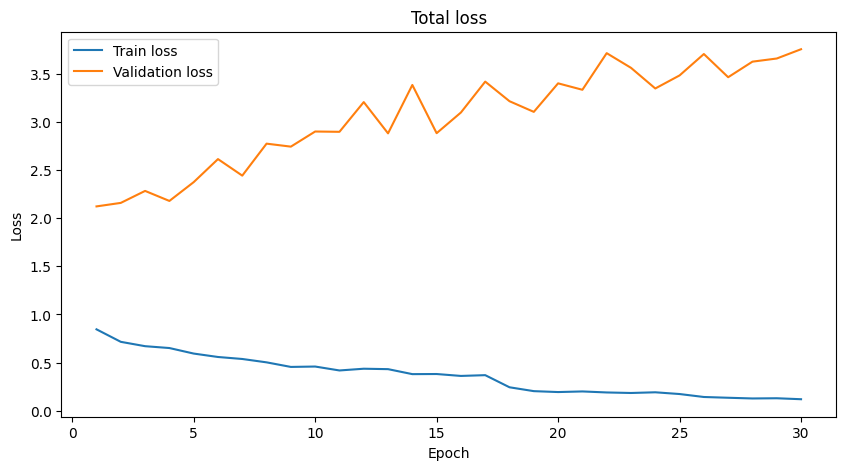

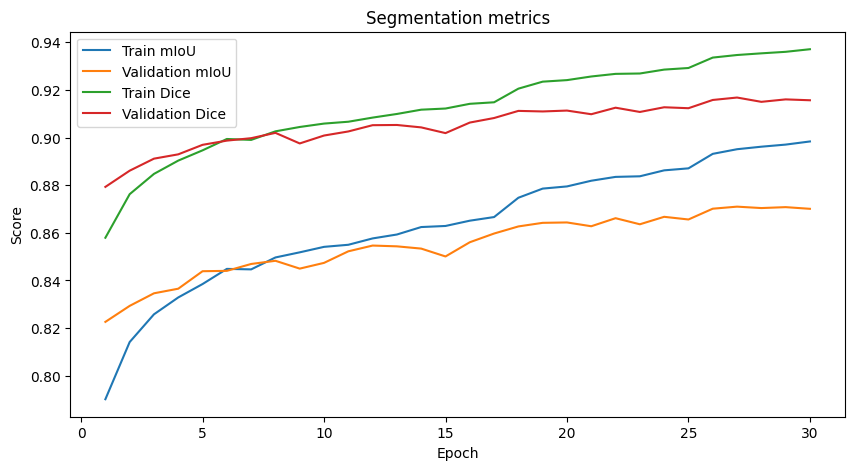

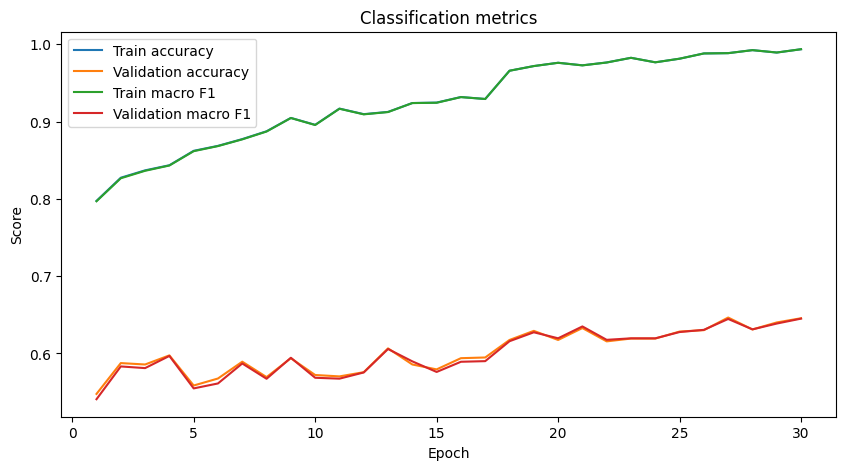

In [ ]:
# Loss/metric curves required for the presentation.
history_df = pd.DataFrame(history)
display(history_df.tail())

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(history_df["epoch"], history_df["train_loss"], label="Train loss")
ax.plot(history_df["epoch"], history_df["val_loss"], label="Validation loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("Total loss")
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(history_df["epoch"], history_df["train_miou"], label="Train mIoU")
ax.plot(history_df["epoch"], history_df["val_miou"], label="Validation mIoU")
ax.plot(history_df["epoch"], history_df["train_dice"], label="Train Dice")
ax.plot(history_df["epoch"], history_df["val_dice"], label="Validation Dice")
ax.set_xlabel("Epoch")
ax.set_ylabel("Score")
ax.set_title("Segmentation metrics")
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(history_df["epoch"], history_df["train_accuracy"], label="Train accuracy")
ax.plot(history_df["epoch"], history_df["val_accuracy"], label="Validation accuracy")
ax.plot(history_df["epoch"], history_df["train_f1_macro"], label="Train macro F1")
ax.plot(history_df["epoch"], history_df["val_f1_macro"], label="Validation macro F1")
ax.set_xlabel("Epoch")
ax.set_ylabel("Score")
ax.set_title("Classification metrics")
ax.legend()
plt.show()


## 16. Final train / validation / test result summary

In [ ]:
# Final evaluation — NO TRAINING

print("Best Attention U-Net checkpoint loaded.")
print("Checkpoint:", best_path)

train_eval_loader = OxfordPetBatchLoader(
    df, train_idx, BATCH_SIZE, False,
    augment=False, device=device
)

val_eval_loader = OxfordPetBatchLoader(
    df, val_idx, BATCH_SIZE, False,
    augment=False, device=device
)

test_eval_loader = OxfordPetBatchLoader(
    df, test_idx, BATCH_SIZE, False,
    augment=False, device=device
)

final_results = {}

for split_name, loader in [
    ("Train", train_eval_loader),
    ("Validation", val_eval_loader),
    ("Test", test_eval_loader),
]:
    print(f"Evaluating {split_name}...")

    final_results[split_name] = run_epoch(
        model,
        loader,
        seg_loss_fn,
        cls_loss_fn,
        optimizer=None
    )

summary = pd.DataFrame(final_results).T[
    [
        "miou",
        "dice",
        "pixel_acc",
        "accuracy",
        "precision_macro",
        "recall_macro",
        "f1_macro"
    ]
]

display(summary)

summary.to_csv(
    RESULT_DIR / "attention_unet_results.csv"
)

print("Saved:", RESULT_DIR / "attention_unet_results.csv")

Best Attention U-Net checkpoint loaded.
Checkpoint: /content/drive/MyDrive/CSE428_Oxford_Pets/checkpoints/attention_unet_best.pt
Evaluating Train...
Evaluating Validation...
Evaluating Test...


,miou,dice,pixel_acc,accuracy,precision_macro,recall_macro,f1_macro
Train,0.903161,0.940109,0.956092,0.999222,0.999229,0.999218,0.999221
Validation,0.870082,0.915651,0.936865,0.645512,0.655059,0.645644,0.645015
Test,0.875616,0.920087,0.941608,0.660018,0.676637,0.660136,0.662656


Saved: /content/drive/MyDrive/CSE428_Oxford_Pets/results/attention_unet_results.csv


In [ ]:
# Final evaluation on train, validation and test.
# The best validation checkpoint is loaded before reporting the final results.
if best_path.exists():
    load_checkpoint(best_path, model)
    print("Loaded best checkpoint:", best_path)

train_eval_loader = OxfordPetBatchLoader(df, train_idx, BATCH_SIZE, False, augment=False, device=device)
val_eval_loader = OxfordPetBatchLoader(df, val_idx, BATCH_SIZE, False, augment=False, device=device)
test_eval_loader = OxfordPetBatchLoader(df, test_idx, BATCH_SIZE, False, augment=False, device=device)

final_results = {}
for split_name, loader in [
    ("Train", train_eval_loader),
    ("Validation", val_eval_loader),
    ("Test", test_eval_loader),
]:
    final_results[split_name] = run_epoch(
        model, loader, seg_loss_fn, cls_loss_fn, optimizer=None
    )

summary = pd.DataFrame(final_results).T[
    [
        "miou", "dice", "pixel_acc",
        "accuracy", "precision_macro", "recall_macro", "f1_macro"
    ]
]
display(summary)
summary.to_csv(RESULT_DIR / "attention_unet_results.csv")
print("Saved:", RESULT_DIR / "attention_unet_results.csv")


Loaded best checkpoint: /content/drive/MyDrive/CSE428_Oxford_Pets/checkpoints/attention_unet_best.pt


## 17. Required demonstration block

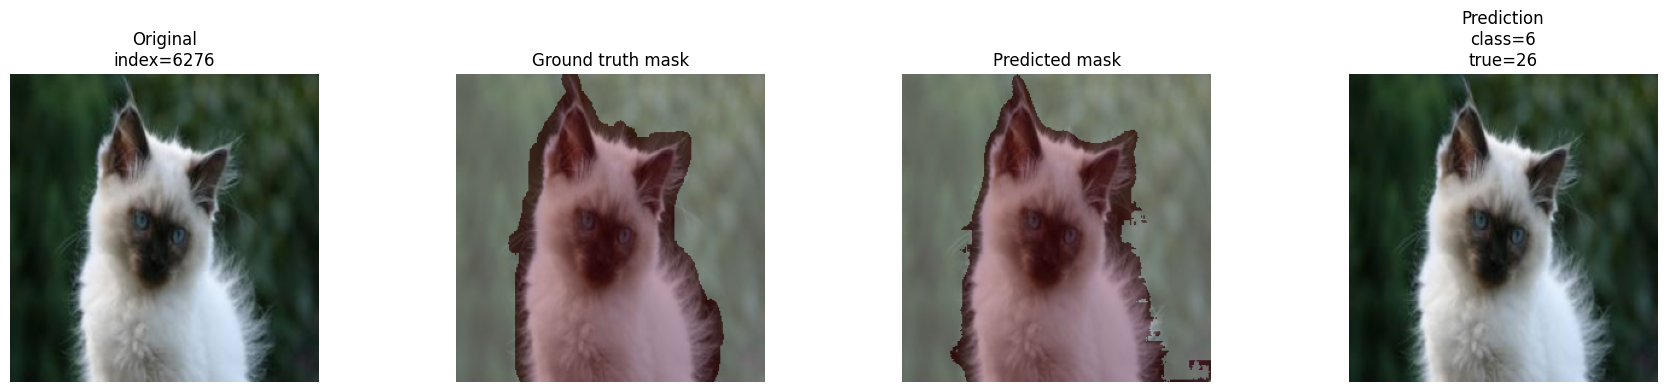

In [ ]:
# Demonstration function.
# Give ANY dataset index; the function runs the model and displays:
# original image, ground-truth overlay, predicted overlay, and classification result.
def predict_index(index, model=model):
    model.eval()
    row = df.iloc[int(index)]
    image, mask = load_pair(row)

    x = torch.tensor(image, dtype=torch.float32, device=device).permute(2, 0, 1).unsqueeze(0)

    with torch.no_grad():
        seg_logits, cls_logits = model(x)
        pred_mask = (torch.sigmoid(seg_logits)[0] >= 0.5).float().cpu().numpy()
        pred_class = int(cls_logits.argmax(dim=1).item())

    fig, axes = plt.subplots(1, 4, figsize=(18, 4))

    axes[0].imshow(image)
    axes[0].axis("off")
    axes[0].set_title(f"Original\nindex={index}")

    axes[1].imshow(image)
    axes[1].imshow(mask, cmap="Reds", alpha=0.35)
    axes[1].axis("off")
    axes[1].set_title("Ground truth mask")

    axes[2].imshow(image)
    axes[2].imshow(pred_mask, cmap="Reds", alpha=0.35)
    axes[2].axis("off")
    axes[2].set_title("Predicted mask")

    axes[3].imshow(image)
    axes[3].axis("off")
    axes[3].set_title(
        f"Prediction\nclass={pred_class}\ntrue={int(row['class_id'])}"
    )

    plt.tight_layout()
    plt.show()

# Example for presentation:
predict_index(int(test_idx[1]))


## Attention U-Net checklist

- [x] Same Oxford-IIIT Pet dataset and preprocessing pipeline
- [x] Boundary pixels converted to foreground
- [x] 3×3 random mask-overlay visualization
- [x] Stratified train/validation/test split
- [x] Augmentation
- [x] Attention U-Net encoder/bottleneck/decoder
- [x] Attention gates on skip connections
- [x] Same classifier head as Base U-Net
- [x] Previous classifier/encoder/bottleneck weights reused when Base checkpoint exists
- [x] Joint segmentation + classification training
- [x] Required segmentation metrics on train/validation/test
- [x] Required classification metrics on train/validation/test
- [x] Per-epoch statistics and curves
- [x] Arbitrary-index demonstration function
- [x] `torch.save()` best/last checkpoints and resume support

**Important:** numerical results are generated by running the notebook; no fabricated scores are included.